# Day 15 · CNN basics: a convolutional network for MNIST in PyTorch

**Course lab:** `CV-Week2-Lecture7.ipynb` (Day 15: CNN Basics)
**Notes chapter:** `week-2/notes/08_cnn_basics.md` (deeper reading: `week-2-3/notes/00_deep_learning_basics.md` and `week-2-3/notebooks/01_neural_network_building_blocks.ipynb`, but this notebook stands on its own)
**Run time:** about 5–8 minutes on a laptop CPU, almost all of it the one training epoch (much faster with a GPU). Downloads MNIST (about 12 MB) the first time.

**What you will learn**
- What convolution, **feature maps**, **stride**, **padding**, **pooling** and **flatten** do, with the shapes worked out step by step.
- Why the course's `fc1` has exactly **9216** inputs (the output-size formula).
- The course CNN, training loop and testing loop, line by line: `Normalize((0.1307,), (0.3081,))`, `log_softmax` + `nll_loss`, Adam, dropout, `model.train()` / `model.eval()`, `torch.no_grad()`.
- What the network learned: its first-layer filters and the feature maps it produces.
- The mini project, done for real: recognising digits **you draw**, and the preprocessing without which it fails.

## 1 · The ideas in plain language

On Day 14 we slid a hand-made edge kernel over an image (convolution = sliding dot product) and saw that a dense network ignores which pixels are neighbours. A **CNN** keeps the sliding kernels but **learns** their numbers.

> **Analogy (Key Concepts):** a CNN is a detective with magnifying glasses (filters) looking for clues (features) everywhere in the image. Early layers find edges and corners; deeper layers combine them into strokes, loops and whole digits.

**The flow of data** (Key Concepts tip): **Input → Convolution → (ReLU) → Pooling → Flatten → Fully connected → Output**

| Word | Plain meaning |
|---|---|
| **Kernel / filter** | a small grid of learned weights (here 3×3) that slides over the image |
| **Feature map** | the output image of one filter: how strongly that pattern appears at each position |
| **Stride** | the step size of the slide (stride 2 = skip every other position → smaller output) |
| **Padding** | a border of zeros around the input so the output does not shrink and edge pixels are covered |
| **Pooling** | summarise each small region (max pooling keeps the strongest response) → smaller maps, tolerance to small shifts, less computation |
| **Flatten** | reshape the stack of feature maps into one long vector for the fully connected layers |
| **Activation (ReLU)** | max(0, x): adds non-linearity; without it stacked layers collapse into one linear map |

**Output size of a convolution or pooling layer** (learn this formula):

  **output = (W − K + 2P) / S + 1**  (W = input size, K = kernel size, P = padding, S = stride; round down)

In [1]:
%matplotlib inline
import time
import numpy as np
import matplotlib.pyplot as plt
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

torch.set_num_threads(2)                 # optional: leave CPU cores free for the rest of the laptop
torch.manual_seed(0)                     # repeatable results (the course notebook had no seed)
plt.rcParams["figure.dpi"] = 80
print("PyTorch", torch.__version__, "| GPU available:", torch.cuda.is_available())

PyTorch 2.14.1+cu130 | GPU available: False


## 2 · The course code: data and normalisation

In [2]:
# Transform: normalize MNIST digits
transform = transforms.Compose([
    transforms.ToTensor(),                         # PIL image 0-255 -> float tensor 0.0-1.0, shape (1, 28, 28)
    transforms.Normalize((0.1307,), (0.3081,))     # (x - mean) / std, using MNIST's own mean and std
])

# Load MNIST dataset (downloads into ./data the first time)
train_dataset = datasets.MNIST('./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST('./data', train=False, download=True, transform=transform)   # course omitted download=True here

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)      # 64 images per training step, new order each epoch
test_loader = DataLoader(test_dataset, batch_size=1000, shuffle=False)     # bigger batches are fine when not training
print(len(train_dataset), "training images,", len(test_dataset), "test images,", len(train_loader), "batches per epoch")

60000 training images, 10000 test images, 938 batches per epoch


MNIST training pixels: mean = 0.1307, std = 0.3081
one normalised image: shape (1, 28, 28), min -0.424, max 2.821, label 5
background pixels become (0 - 0.1307) / 0.3081 = -0.4242


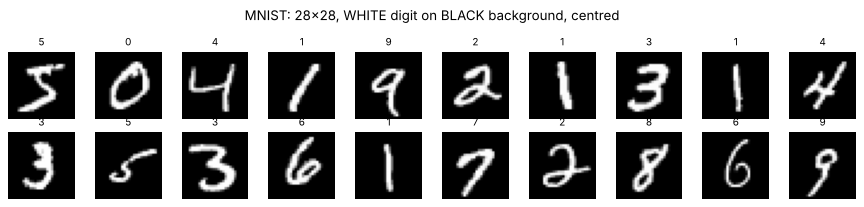

In [3]:
# Where do 0.1307 and 0.3081 come from? They are the mean and standard deviation of all MNIST training pixels (scaled 0-1).
raw = train_dataset.data.float() / 255
print(f"MNIST training pixels: mean = {raw.mean():.4f}, std = {raw.std():.4f}")
x0, y0 = train_dataset[0]
print(f"one normalised image: shape {tuple(x0.shape)}, min {x0.min():.3f}, max {x0.max():.3f}, label {y0}")
print("background pixels become (0 - 0.1307) / 0.3081 =", round((0 - 0.1307) / 0.3081, 4))

fig, axes = plt.subplots(2, 10, figsize=(11, 2.6))
for a, i in zip(axes.ravel(), range(20)):
    img, lab = train_dataset[i]
    a.imshow(img[0], cmap="gray"); a.set_title(str(lab), fontsize=9); a.axis("off")
plt.suptitle("MNIST: 28x28, WHITE digit on BLACK background, centred"); plt.tight_layout(); plt.show()

**Why normalise?** After `Normalize` the pixels have mean ≈ 0 and standard deviation ≈ 1. Inputs on this scale keep the early layers' outputs in a sensible range and make gradient descent faster and more stable (Day 14, section 5). The same `transform` must be used for **every** image the model ever sees, including your own drawings (section 9).

## 3 · Stride, padding, pooling and flatten, step by step

In [4]:
x = torch.arange(1, 37, dtype=torch.float32).reshape(1, 1, 6, 6)    # a 6x6 "image" in (batch, channels, H, W) form
print("input shape:", tuple(x.shape))
for k, s, p in [(3, 1, 0), (3, 1, 1), (3, 2, 0), (3, 2, 1), (5, 1, 0)]:
    conv = nn.Conv2d(1, 1, kernel_size=k, stride=s, padding=p)
    out = conv(x)
    print(f"kernel {k}, stride {s}, padding {p}: output {tuple(out.shape[2:])}   formula (6 - {k} + 2*{p}) / {s} + 1 = {(6 - k + 2 * p) // s + 1}")

pool_in = torch.tensor([[1., 3, 2, 1], [4, 6, 5, 0], [7, 2, 9, 8], [1, 0, 3, 4]]).reshape(1, 1, 4, 4)
print("\nmax pooling 2x2 (stride 2) keeps the biggest number in each 2x2 block:")
print(pool_in[0, 0].int().numpy(), "\n->\n", F.max_pool2d(pool_in, 2)[0, 0].int().numpy())
print("average pooling instead:\n", F.avg_pool2d(pool_in, 2)[0, 0].numpy())

stack = torch.randn(1, 64, 12, 12)
print("\nflatten: a stack of 64 feature maps of 12x12", tuple(stack.shape), "->", tuple(torch.flatten(stack, 1).shape),
      "(start_dim=1 keeps the batch dimension)")

input shape: (1, 1, 6, 6)
kernel 3, stride 1, padding 0: output (4, 4)   formula (6 - 3 + 2*0) / 1 + 1 = 4
kernel 3, stride 1, padding 1: output (6, 6)   formula (6 - 3 + 2*1) / 1 + 1 = 6
kernel 3, stride 2, padding 0: output (2, 2)   formula (6 - 3 + 2*0) / 2 + 1 = 2
kernel 3, stride 2, padding 1: output (3, 3)   formula (6 - 3 + 2*1) / 2 + 1 = 3
kernel 5, stride 1, padding 0: output (2, 2)   formula (6 - 5 + 2*0) / 1 + 1 = 2

max pooling 2x2 (stride 2) keeps the biggest number in each 2x2 block:
[[1 3 2 1]
 [4 6 5 0]
 [7 2 9 8]
 [1 0 3 4]] 
->
 [[6 5]
 [7 9]]
average pooling instead:
 [[3.5 2. ]
 [2.5 6. ]]

flatten: a stack of 64 feature maps of 12x12 (1, 64, 12, 12) -> (1, 9216) (start_dim=1 keeps the batch dimension)


In [5]:
# Padding demo: zeros around the border
padded = F.pad(x, (1, 1, 1, 1))
print("6x6 input with padding=1 becomes", tuple(padded.shape[2:]), "; first two rows:\n", padded[0, 0, :2].int().numpy())

# Pooling gives tolerance to small shifts: shift a pattern by 1 pixel, compare after 2x2 max pooling
a = torch.zeros(1, 1, 8, 8); a[0, 0, 2, 2] = 1
b = torch.zeros(1, 1, 8, 8); b[0, 0, 2, 3] = 1          # same dot, 1 pixel to the right
print("before pooling, identical?", torch.equal(a, b), "| after 2x2 max pooling, identical?", torch.equal(F.max_pool2d(a, 2), F.max_pool2d(b, 2)))

6x6 input with padding=1 becomes (8, 8) ; first two rows:
 [[0 0 0 0 0 0 0 0]
 [0 1 2 3 4 5 6 0]]
before pooling, identical? False | after 2x2 max pooling, identical? True


That last line is the "translation invariance" the Key Concepts mention: after pooling, a small shift (within the pooling window) gives the same result. (A shift that crosses a pooling-block boundary still changes the output; pooling gives *some* tolerance, not full invariance.)

## 4 · The course CNN (unchanged), and why `fc1` has 9216 inputs

In [6]:
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, 3, 1)      # 1 input channel (grey) -> 32 feature maps, 3x3 kernels, stride 1, no padding
        self.conv2 = nn.Conv2d(32, 64, 3, 1)     # 32 maps in -> 64 maps out; each kernel is 3x3x32
        self.dropout1 = nn.Dropout(0.25)         # during training, randomly zero 25% of values
        self.dropout2 = nn.Dropout(0.5)          # ... and 50% before the last layer
        self.fc1 = nn.Linear(9216, 128)          # 9216 = 64 maps x 12 x 12 (worked out below)
        self.fc2 = nn.Linear(128, 10)            # 10 scores, one per digit

    def forward(self, x):
        x = self.conv1(x)
        x = F.relu(x)
        x = self.conv2(x)
        x = F.relu(x)
        x = F.max_pool2d(x, 2)
        x = self.dropout1(x)
        x = torch.flatten(x, 1)
        x = self.fc1(x)
        x = F.relu(x)
        x = self.dropout2(x)
        x = self.fc2(x)
        output = F.log_softmax(x, dim=1)
        return output

model = CNN()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [7]:
# Follow one image through the network and print the shape after every step
model.eval()
x = train_dataset[0][0].unsqueeze(0)                    # (1, 1, 28, 28)
steps = [("input", lambda t: t), ("conv1 (3x3, 32 filters)", model.conv1), ("ReLU", F.relu),
         ("conv2 (3x3, 64 filters)", model.conv2), ("ReLU", F.relu), ("max_pool2d(2)", lambda t: F.max_pool2d(t, 2)),
         ("dropout1", model.dropout1), ("flatten", lambda t: torch.flatten(t, 1)), ("fc1", model.fc1), ("ReLU", F.relu),
         ("dropout2", model.dropout2), ("fc2", model.fc2), ("log_softmax", lambda t: F.log_softmax(t, dim=1))]
with torch.no_grad():
    for name, fn in steps:
        x = fn(x)
        print(f"{name:26s} -> {str(tuple(x.shape)):18s} = {x.numel():>6,} numbers")

print("\nconv1: (28 - 3 + 2*0)/1 + 1 = 26  -> 26x26")
print("conv2: (26 - 3 + 2*0)/1 + 1 = 24  -> 24x24")
print("pool : (24 - 2)/2 + 1       = 12  -> 12x12")
print("flatten: 64 maps x 12 x 12  =", 64 * 12 * 12, "-> that is why fc1 = nn.Linear(9216, 128)")

input                      -> (1, 1, 28, 28)     =    784 numbers
conv1 (3x3, 32 filters)    -> (1, 32, 26, 26)    = 21,632 numbers
ReLU                       -> (1, 32, 26, 26)    = 21,632 numbers
conv2 (3x3, 64 filters)    -> (1, 64, 24, 24)    = 36,864 numbers
ReLU                       -> (1, 64, 24, 24)    = 36,864 numbers
max_pool2d(2)              -> (1, 64, 12, 12)    =  9,216 numbers
dropout1                   -> (1, 64, 12, 12)    =  9,216 numbers
flatten                    -> (1, 9216)          =  9,216 numbers
fc1                        -> (1, 128)           =    128 numbers
ReLU                       -> (1, 128)           =    128 numbers
dropout2                   -> (1, 128)           =    128 numbers
fc2                        -> (1, 10)            =     10 numbers
log_softmax                -> (1, 10)            =     10 numbers

conv1: (28 - 3 + 2*0)/1 + 1 = 26  -> 26x26
conv2: (26 - 3 + 2*0)/1 + 1 = 24  -> 24x24
pool : (24 - 2)/2 + 1       = 12  -> 12x12
flatten: 64 

In [8]:
print(f"{'layer':8s} {'weights shape':>18s} {'parameters':>11s}")
total = 0
for name, layer in [("conv1", model.conv1), ("conv2", model.conv2), ("fc1", model.fc1), ("fc2", model.fc2)]:
    n = sum(p.numel() for p in layer.parameters()); total += n
    print(f"{name:8s} {str(tuple(layer.weight.shape)):>18s} {n:>11,}")
print(f"{'total':8s} {'':>18s} {total:>11,}")
print(f"fc1 alone holds {sum(p.numel() for p in model.fc1.parameters()) / total:.0%} of all parameters")

layer         weights shape  parameters
conv1         (32, 1, 3, 3)         320
conv2        (64, 32, 3, 3)      18,496
fc1             (128, 9216)   1,179,776
fc2               (10, 128)       1,290
total                         1,199,882
fc1 alone holds 98% of all parameters


**Things to notice**
- The two conv layers together have under 20,000 parameters, yet they do all the "seeing". The single dense layer `fc1` has over 1.1 million: the Day 14 lesson again (dense layers are expensive). Modern CNNs replace big dense layers with global average pooling.
- No padding is used, so each 3×3 conv shrinks the image by 2 pixels (28 → 26 → 24).
- If you change the architecture (e.g. add `padding=1`, or another pooling layer), **9216 is no longer correct** and you get `mat1 and mat2 shapes cannot be multiplied`. Recompute with the formula, or print the shape after `flatten` as above.

**Dropout** randomly switches off neurons during training (25% after pooling, 50% before the last layer). The network cannot rely on any single neuron, which reduces overfitting. It is automatically **turned off** in `model.eval()` mode.

**`log_softmax` + `nll_loss` = cross-entropy.** `softmax` turns the 10 scores into probabilities that sum to 1; `log_softmax` is its logarithm (numerically safer). `nll_loss` (negative log-likelihood) picks −log(probability of the correct class): 0 if the model is certain and right, large if it gave the right answer a low probability. Together they are exactly `F.cross_entropy` applied to the raw scores:

In [9]:
scores = torch.tensor([[2.0, 0.5, -1.0, 0.1, 0.0, 0.3, -0.5, 1.0, 0.2, -2.0]])   # raw fc2 output for one image
target = torch.tensor([0])                                                        # the true class is 0
print("softmax probabilities:", F.softmax(scores, dim=1).numpy().round(3), "sum =", F.softmax(scores, dim=1).sum().item())
print("nll_loss(log_softmax) =", F.nll_loss(F.log_softmax(scores, dim=1), target).item())
print("cross_entropy(scores) =", F.cross_entropy(scores, target).item())
print("-log(p of class 0)    =", -torch.log(F.softmax(scores, dim=1)[0, 0]).item())

softmax probabilities: [[0.421 0.094 0.021 0.063 0.057 0.077 0.035 0.155 0.07  0.008]] sum = 1.0
nll_loss(log_softmax) = 0.8646115064620972
cross_entropy(scores) = 0.8646115064620972
-log(p of class 0)    = 0.8646114468574524


## 5 · Training loop (course code, plus a loss record)

One **training step** = the 5 lines every PyTorch training loop has:
1. `optimizer.zero_grad()`: clear the gradients from the previous step (PyTorch *adds* gradients up otherwise).
2. `output = model(data)`: **forward pass**.
3. `loss = F.nll_loss(output, target)`: how wrong were we on this batch?
4. `loss.backward()`: **backpropagation**, computing the gradient of the loss for every weight.
5. `optimizer.step()`: move every weight a little downhill.

**Adam** is gradient descent with two improvements: each weight gets its own adaptive step size, and it keeps a running average of past gradients ("momentum") to smooth the path. `lr=0.001` is its standard starting learning rate.

`model.train()` switches dropout **on**. The only change from the course: we also store every batch's loss so we can plot the training curve. The course trained for 2 epochs; to keep this notebook's run time reasonable on a CPU we train **1 epoch** (`EPOCHS = 2` gives the course's setting).

In [10]:
losses = []                                         # added: one loss value per batch, for the plot

def train(model, device, train_loader, optimizer, epoch):
    model.train()                                   # dropout ON
    for batch_idx, (data, target) in enumerate(train_loader):
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        output = model(data)
        loss = F.nll_loss(output, target)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())                  # added
        if batch_idx % 100 == 0:
            print(f'Train Epoch: {epoch} [{batch_idx*len(data)}/{len(train_loader.dataset)}] Loss: {loss.item():.6f}')

## 6 · Testing loop (course code)

- `model.eval()`: dropout **off** (use the whole network).
- `with torch.no_grad()`: do not record operations for backpropagation: faster and uses less memory, and we are not learning here.
- `reduction='sum'` adds up the loss over the batch so we can average over all 10,000 images at the end.
- `output.argmax(dim=1)` = the class with the highest score = the prediction.

In [11]:
def test(model, device, test_loader):
    model.eval()                                    # dropout OFF
    test_loss = 0
    correct = 0
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = model(data)
            test_loss += F.nll_loss(output, target, reduction='sum').item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()
    test_loss /= len(test_loader.dataset)
    accuracy = 100. * correct / len(test_loader.dataset)
    print(f'Test set: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(test_loader.dataset)} ({accuracy:.2f}%)')
    return accuracy

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
print("Before training (random weights):")
acc0 = test(model, device, test_loader)

Before training (random weights):


Test set: Average loss: 2.3034, Accuracy: 1042/10000 (10.42%)


In [12]:
EPOCHS = 1                                          # the course used 2: range(1, 3)
t0 = time.perf_counter()
for epoch in range(1, EPOCHS + 1):
    train(model, device, train_loader, optimizer, epoch)
    acc = test(model, device, test_loader)
train_time = time.perf_counter() - t0
print(f"\ntraining + testing took {train_time / 60:.1f} minutes on {device}")
torch.save(model.state_dict(), "data/mnist_cnn.pt")          # keep the trained weights (data/ is not committed)

Train Epoch: 1 [0/60000] Loss: 2.309885


Train Epoch: 1 [6400/60000] Loss: 0.277482


Train Epoch: 1 [12800/60000] Loss: 0.111392


Train Epoch: 1 [19200/60000] Loss: 0.171644


Train Epoch: 1 [25600/60000] Loss: 0.048270


...

Train Epoch: 1 [38400/60000] Loss: 0.111809


Train Epoch: 1 [44800/60000] Loss: 0.023685


Train Epoch: 1 [51200/60000] Loss: 0.023061


Train Epoch: 1 [57600/60000] Loss: 0.081401


Test set: Average loss: 0.0458, Accuracy: 9856/10000 (98.56%)

training + testing took 5.4 minutes on cpu


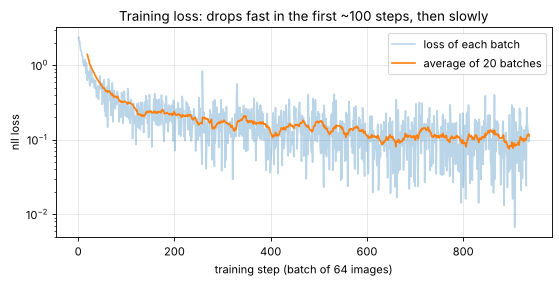

loss: first batch 2.310 (about -log(1/10) = 2.303, a random guess) -> mean of last 100 batches 0.106


In [13]:
smooth = np.convolve(losses, np.ones(20) / 20, mode="valid")
plt.figure(figsize=(8, 3.4))
plt.plot(losses, alpha=.3, label="loss of each batch")
plt.plot(range(19, len(losses)), smooth, label="average of 20 batches")
plt.yscale("log"); plt.xlabel("training step (batch of 64 images)"); plt.ylabel("nll loss")
plt.title("Training loss: drops fast in the first ~100 steps, then slowly"); plt.legend(); plt.grid(alpha=.3); plt.show()
print(f"loss: first batch {losses[0]:.3f} (about -log(1/10) = {np.log(10):.3f}, a random guess) -> mean of last 100 batches {np.mean(losses[-100:]):.3f}")

The very first loss is about 2.30 = −log(1/10): a random network gives each digit a probability of about 1/10. The noisy curve is normal: each batch contains different images.

## 7 · Which digits does it get wrong?

144 mistakes out of 10000


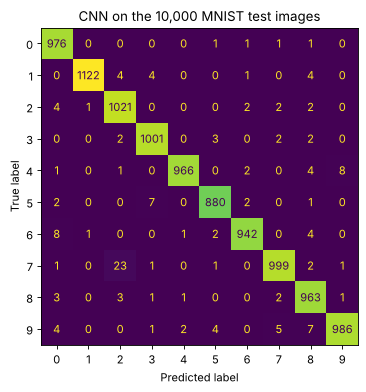

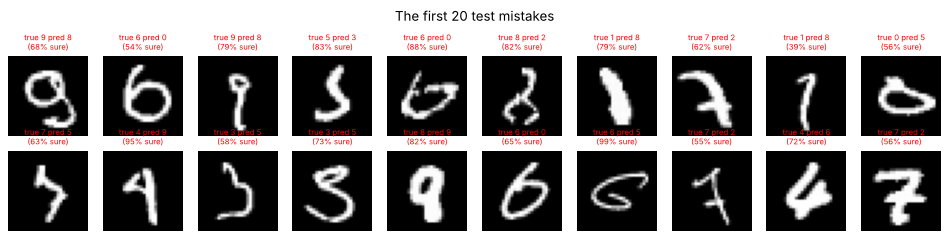

In [14]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
model.eval()
preds, targets, probs = [], [], []
with torch.no_grad():
    for data, target in test_loader:
        out = model(data.to(device))
        preds.append(out.argmax(1).cpu()); targets.append(target); probs.append(out.exp().max(1).values.cpu())
preds, targets, probs = torch.cat(preds).numpy(), torch.cat(targets).numpy(), torch.cat(probs).numpy()
wrong = np.where(preds != targets)[0]
print(f"{len(wrong)} mistakes out of {len(targets)}")
fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(confusion_matrix(targets, preds)).plot(ax=ax, colorbar=False)
ax.set_title("CNN on the 10,000 MNIST test images"); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 10, figsize=(12, 3))
for a, i in zip(axes.ravel(), wrong[:20]):
    a.imshow(test_dataset[i][0][0], cmap="gray"); a.axis("off")
    a.set_title(f"true {targets[i]} pred {preds[i]}\n({probs[i]:.0%} sure)", fontsize=7, color="red")
plt.suptitle("The first 20 test mistakes"); plt.tight_layout(); plt.show()

Many of the mistakes are genuinely ambiguous or badly written digits. Note that the model is sometimes **confidently wrong**: a high softmax probability is not a guarantee.

## 8 · What did the network learn? Filters and feature maps

The 32 first-layer filters are 3×3 grids of learned numbers. Compare them with Day 14's hand-made Sobel kernel: many are edge or stroke detectors in different directions, **learned from data**.

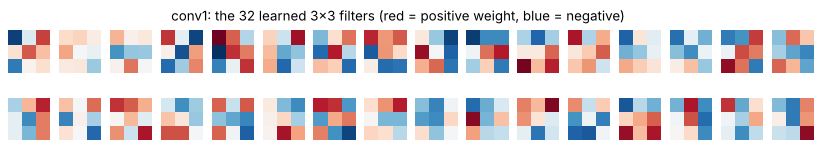

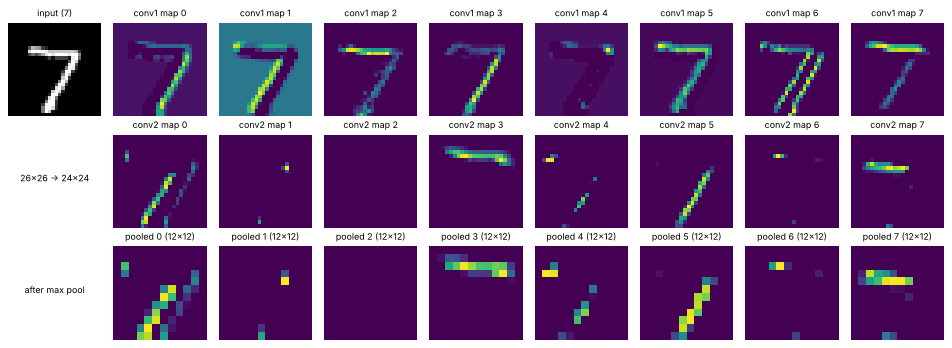

In [15]:
W1 = model.conv1.weight.detach().cpu()[:, 0]          # (32, 3, 3)
fig, axes = plt.subplots(2, 16, figsize=(13, 2))
for a, w in zip(axes.ravel(), W1):
    a.imshow(w, cmap="RdBu", vmin=-W1.abs().max(), vmax=W1.abs().max()); a.axis("off")
plt.suptitle("conv1: the 32 learned 3x3 filters (red = positive weight, blue = negative)"); plt.show()

img, lab = test_dataset[0]
with torch.no_grad():
    f1 = F.relu(model.conv1(img[None].to(device)))[0].cpu()
    f2 = F.relu(model.conv2(f1[None].to(device)))[0].cpu()
    p2 = F.max_pool2d(f2[None], 2)[0]
fig, axes = plt.subplots(3, 9, figsize=(12, 4.4))
axes[0, 0].imshow(img[0], cmap="gray"); axes[0, 0].set_title(f"input ({lab})", fontsize=8)
for j in range(8):
    axes[0, j + 1].imshow(f1[j], cmap="viridis"); axes[0, j + 1].set_title(f"conv1 map {j}", fontsize=8)
    axes[1, j + 1].imshow(f2[j], cmap="viridis"); axes[1, j + 1].set_title(f"conv2 map {j}", fontsize=8)
    axes[2, j + 1].imshow(p2[j], cmap="viridis"); axes[2, j + 1].set_title(f"pooled {j} (12x12)", fontsize=8)
for a in axes.ravel(): a.axis("off")
axes[1, 0].text(0.5, 0.5, "26x26 -> 24x24", ha="center", fontsize=8); axes[2, 0].text(0.5, 0.5, "after max pool", ha="center", fontsize=8)
plt.tight_layout(); plt.show()

Each **feature map** is bright where its filter's pattern appears: some light up on left edges of strokes, some on bottom edges, some on the whole stroke. conv2 maps combine conv1's maps into more complex patterns, and pooling halves their size while keeping the strong responses.

## 9 · Mini project: a digit classifier for digits *you* draw

The course stops at *"Try feeding custom digit images or drawing digits"* with no code. Here it is. We draw 30 digits in code (pen-stroke style and two fonts), deliberately **dark ink on white paper, small and off-centre**, like a photo of a page. Then we compare four preprocessing pipelines.

What MNIST images look like, so what our input must look like:
- 28×28 pixels, **white digit on black** background,
- the digit is scaled to fit a **20×20 box** and **centred** (by its centre of mass) in the 28×28 frame,
- pixel values scaled to 0–1 and then **normalised** with mean 0.1307 and std 0.3081.

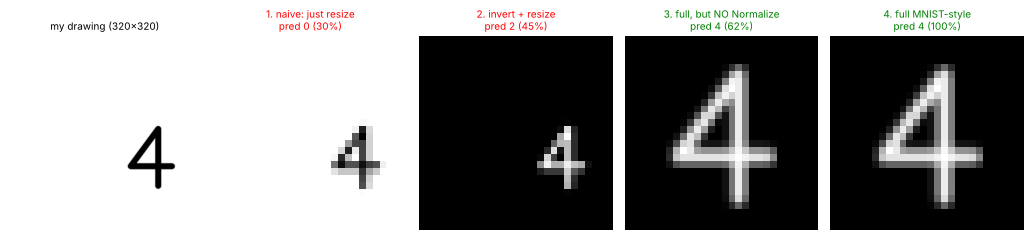

In [16]:
def draw_digit(d, style, size=320, rng=None):
    """Dark digit on white paper, smaller than the page and not centred."""
    rng = rng or np.random.default_rng(d)
    tile = np.full((200, 200), 255, np.uint8)
    if style == "pen":
        strokes = {0: [(100, 30), (60, 60), (55, 120), (80, 170), (120, 170), (145, 120), (140, 60), (100, 30)],
                   1: [(80, 60), (110, 30), (110, 175)], 2: [(55, 65), (90, 30), (135, 45), (140, 85), (60, 170), (150, 170)],
                   3: [(55, 45), (130, 35), (100, 95), (145, 130), (115, 172), (55, 165)], 4: [(120, 175), (120, 30), (50, 125), (155, 125)],
                   5: [(140, 30), (70, 30), (62, 95), (125, 95), (140, 140), (105, 172), (55, 160)],
                   6: [(130, 30), (75, 80), (60, 140), (95, 172), (138, 145), (118, 105), (65, 125)], 7: [(50, 35), (150, 35), (90, 175)],
                   8: [(100, 100), (60, 60), (100, 28), (140, 60), (100, 100), (55, 140), (100, 175), (145, 140), (100, 100)],
                   9: [(135, 70), (100, 30), (60, 65), (95, 100), (135, 70), (125, 175)]}
        cv2.polylines(tile, [np.array(strokes[d], np.int32)], False, 0, 14, cv2.LINE_AA)
    else:
        font = cv2.FONT_HERSHEY_SIMPLEX if style == "font A" else cv2.FONT_HERSHEY_SCRIPT_SIMPLEX
        cv2.putText(tile, str(d), (40, 165), font, 6, 0, 14, cv2.LINE_AA)
    page = np.full((size, size), 255, np.uint8)
    tile = cv2.resize(tile, (130, 130), interpolation=cv2.INTER_AREA)
    oy, ox = rng.integers(10, size - 140, 2)
    page[oy:oy + 130, ox:ox + 130] = tile
    return page

def to_mnist(img, invert=True, crop_centre=True, normalise=True):
    """Grey image of one digit -> normalised (1, 1, 28, 28) tensor like MNIST. Flags let us switch steps off."""
    g = 255 - img if invert else img.copy()                       # 1) MNIST is white-on-black
    if crop_centre:
        ys, xs = np.nonzero(g > 50)                               # 2) crop to the digit
        g = g[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
        h, w = g.shape; s = 20 / max(h, w)                        # 3) fit the longest side into 20 pixels (keep aspect)
        g = cv2.resize(g, (max(1, round(w * s)), max(1, round(h * s))), interpolation=cv2.INTER_AREA)
        canvas = np.zeros((28, 28), np.uint8)                     # 4) paste into 28x28 ...
        h, w = g.shape; y0, x0 = (28 - h) // 2, (28 - w) // 2
        canvas[y0:y0 + h, x0:x0 + w] = g
        m = cv2.moments(canvas)                                   # ... and shift so the centre of mass is in the middle
        dx, dy = 14 - m["m10"] / m["m00"], 14 - m["m01"] / m["m00"]
        g = cv2.warpAffine(canvas, np.float32([[1, 0, dx], [0, 1, dy]]), (28, 28))
    else:
        g = cv2.resize(g, (28, 28), interpolation=cv2.INTER_AREA)  # naive: squash the whole page to 28x28
    t = torch.tensor(g, dtype=torch.float32)[None, None] / 255.0    # 5) 0-255 -> 0-1 (what ToTensor does)
    if normalise:
        t = (t - 0.1307) / 0.3081                                 # 6) the same Normalize as in training
    return t

def predict(t):
    model.eval()
    with torch.no_grad():
        p = model(t.to(device)).exp()[0].cpu()
    return int(p.argmax()), float(p.max())

page = draw_digit(4, "pen")
variants = {
    "1. naive: just resize": dict(invert=False, crop_centre=False, normalise=True),
    "2. invert + resize": dict(invert=True, crop_centre=False, normalise=True),
    "3. full, but NO Normalize": dict(invert=True, crop_centre=True, normalise=False),
    "4. full MNIST-style": dict(invert=True, crop_centre=True, normalise=True),
}
fig, axes = plt.subplots(1, 5, figsize=(13, 2.9))
axes[0].imshow(page, cmap="gray"); axes[0].set_title("my drawing (320x320)", fontsize=9)
for a, (name, kw) in zip(axes[1:], variants.items()):
    t = to_mnist(page, **kw); p, c = predict(t)
    a.imshow(t[0, 0], cmap="gray"); a.set_title(f"{name}\npred {p} ({c:.0%})", fontsize=9, color="green" if p == 4 else "red")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

1. naive: just resize       :  2/30 correct | mean confidence 35%


2. invert + resize          :  3/30 correct | mean confidence 47%


3. full, but NO Normalize   : 29/30 correct | mean confidence 58%


4. full MNIST-style         : 29/30 correct | mean confidence 93%


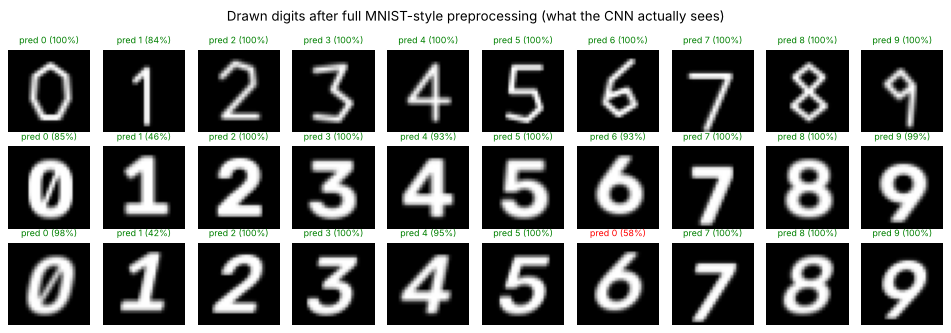

In [17]:
styles = ["pen", "font A", "font B"]
pages = {(s, d): draw_digit(d, s, rng=np.random.default_rng(100 * i + d)) for i, s in enumerate(styles) for d in range(10)}
for name, kw in variants.items():
    res = [predict(to_mnist(pg, **kw)) + (d,) for (s, d), pg in pages.items()]
    ok = sum(p == d for p, c, d in res)
    print(f"{name:28s}: {ok:>2}/30 correct | mean confidence {np.mean([c for p, c, d in res]):.0%}")

fig, axes = plt.subplots(3, 10, figsize=(12, 4.2))
for r, s in enumerate(styles):
    for d in range(10):
        t = to_mnist(pages[(s, d)]); p, c = predict(t)
        axes[r, d].imshow(t[0, 0], cmap="gray"); axes[r, d].axis("off")
        axes[r, d].set_title(f"pred {p} ({c:.0%})", fontsize=8, color="green" if p == d else "red")
plt.suptitle("Drawn digits after full MNIST-style preprocessing (what the CNN actually sees)"); plt.tight_layout(); plt.show()

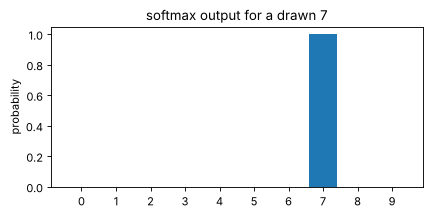

In [18]:
# The model's full opinion for one drawing: softmax probabilities of all 10 classes
d = 7
t = to_mnist(pages[("pen", d)])
with torch.no_grad():
    p = model(t.to(device)).exp()[0].cpu().numpy()
plt.figure(figsize=(6, 2.6)); plt.bar(range(10), p); plt.xticks(range(10))
plt.title(f"softmax output for a drawn {d}"); plt.ylabel("probability"); plt.show()

**What this shows** (counts printed above): the network itself is the same in all four rows; only the preprocessing changes. Feeding a black-on-white page squashed to 28×28 gives nonsense (2 of 30 right); inverting alone barely helps (3 of 30) because the digit is still tiny and off-centre. Once the digit is **inverted, cropped, scaled to 20×20 and centred**, 29 of 30 are right. Forgetting `Normalize` did *not* change the number of correct answers in this run (29/30 either way), but the network became much less sure of itself (mean confidence 58% instead of 93%; the "4" above drops from 100% to 62%): its inputs are on a scale it never saw in training, so it is working "out of distribution" and could easily tip over on harder digits. Always apply the same transform as in training. The one remaining mistake (a script-font 6 read as 0) is a drawing style unlike MNIST's handwriting.

**To use a photo of your own handwriting:** `img = cv2.imread("my_digit.jpg", cv2.IMREAD_GRAYSCALE)`, crop to one digit, threshold with Otsu if the lighting is uneven (`cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)`), then `predict(to_mnist(img))`.

## 10 · 🔧 What we changed from the course notebook, and why

The course CNN, training loop and testing loop are correct and run as written; we kept them unchanged (apart from recording the loss). What was missing or fragile:

| # | Course code | Problem | What we did |
|---|---|---|---|
| 1 | Mini project: "Try feeding custom digit images or drawing digits" | **No code at all**: the mini project is not implemented. | Drew 30 digits, wrote MNIST-style preprocessing, and measured what goes wrong without each step. |
| 2 | `datasets.MNIST('./data', train=False, transform=transform)` | No `download=True` for the test set. It only works because the training-set call happens to download all four MNIST files first. | Added `download=True`. |
| 3 | `Normalize((0.1307,), (0.3081,))` unexplained | Magic numbers; students often forget to apply them to new images. | Computed them from the data; showed the effect of forgetting them. |
| 4 | `nn.Linear(9216, 128)` unexplained | Breaks as soon as the architecture changes. | Printed the shape after every layer; output-size formula. |
| 5 | No seed, no loss curve, no confusion matrix, model not saved | Results differ every run; no insight into learning or errors. | `torch.manual_seed(0)`, loss plot, confusion matrix, misclassified examples, `torch.save`. |
| 6 | 2 epochs | About 5 minutes per epoch on a 2-thread laptop CPU (4.7–5.4 min in our runs, including testing). | `EPOCHS = 1` by default (change to 2 to match the course). |
| 7 | Topics in the Key Concepts (feature maps, stride, padding, pooling, flatten) | Not demonstrated in the lab. | Section 3 and section 8. |

## 11 · Results, honestly

All numbers come from the run above.
- Before training the random network scored 10.42% (chance level).
- After **1 epoch** (938 batches, about 5 minutes including testing, on this CPU with 2 threads) the course CNN reached **98.56% on the 10,000 test images** (144 mistakes). The course notebook reports 98.79% after 2 epochs.
- The training loss fell from 2.310 on the first batch (= −log(1/10), a random guess) to an average of 0.106 over the last 100 batches.
- Drawn digits (30): naive resize 2/30, invert + resize 3/30, full preprocessing without Normalize 29/30 (but mean confidence 58%), full MNIST-style preprocessing **29/30** (mean confidence 93%).
- For comparison (Day 11), an RBF SVM on raw MNIST pixels reached 95.9% with 20,000 training images; the CNN beats it after one pass over the data.
- Parameter count: 1,199,882 in total, 98% of them in `fc1`.
- Caveat: one run, one seed; a second epoch, data augmentation or a learning-rate schedule would push test accuracy higher (99%+ is typical for this architecture).

## 12 · Common errors and how to fix them

| Error / symptom | Cause | Fix |
|---|---|---|
| `RuntimeError: mat1 and mat2 shapes cannot be multiplied (64x... and 9216x128)` | Architecture or input size changed, so the flattened size is no longer 9216 | Print `x.shape` after `flatten`; recompute with (W − K + 2P)/S + 1 |
| `RuntimeError: Expected 4D input` / `Given groups=1, weight of size [32, 1, 3, 3], expected input[1, 28, 28]...` | A single image without the batch dimension | `img.unsqueeze(0)` → (1, 1, 28, 28) |
| `Expected all tensors to be on the same device` | Model on GPU, data on CPU (or the reverse) | `data.to(device)` and `model.to(device)` |
| Loss stays at about 2.30 | Not learning: forgot `optimizer.step()`, learning rate far too small/large, or labels wrong | Check the 5-line training step |
| Test accuracy changes between runs of `test()` | Forgot `model.eval()`: dropout still active | Always `model.eval()` before testing / predicting |
| Out of memory / slow testing | Gradients recorded during testing | Wrap evaluation in `with torch.no_grad():` |
| Your own digit is always predicted wrong | Not preprocessed like MNIST (colours, size, centring, Normalize) | Use `to_mnist()` from section 9 |
| `nll_loss` gives strange (negative) values | `nll_loss` fed raw scores or probabilities, not log-probabilities | Use `log_softmax` first, or `F.cross_entropy` on raw scores |
| Download fails | Offline or blocked | Download the four MNIST files by hand into `data/MNIST/raw/` |

## 13 · Try this yourself

1. Set `EPOCHS = 2` (the course setting). How much does test accuracy improve, and how much longer does it take?
2. Add `padding=1` to both conv layers. What must `fc1`'s input size become? (Work it out with the formula first, then check by printing shapes.)
3. Remove the two dropout layers and train again. Compare training loss and test accuracy. Is there more overfitting?
4. Replace `optim.Adam(..., lr=0.001)` with `optim.SGD(model.parameters(), lr=0.01)`. Faster or slower to learn?
5. Make the network smaller: `conv1` with 8 filters and `conv2` with 16. How many parameters? How accurate?
6. Draw a digit in Paint (black on white), save it, and run `predict(to_mnist(cv2.imread(path, 0)))`.
7. Compare with Day 11: the RBF SVM on raw MNIST pixels reached about 96% with 20,000 training images. Why does the CNN do better?

## 14 · Viva questions (with short model answers)

1. **What is a CNN and why is it suited to images?** A neural network whose main layers are convolutions: small learned filters slid over the image. Local connections and weight sharing exploit spatial structure with far fewer parameters than dense layers.
2. **What is a feature map?** The output of one filter over the whole input: a 2-D map of how strongly that pattern appears at each position.
3. **Give the output-size formula and apply it to conv1.** (W − K + 2P)/S + 1 = (28 − 3 + 0)/1 + 1 = 26.
4. **Why does `fc1` have 9216 inputs?** 28 → conv1 → 26 → conv2 → 24 → 2×2 max pool → 12; 64 channels × 12 × 12 = 9216.
5. **What do stride and padding do?** Stride is the step of the sliding window (larger → smaller output); padding adds a border (usually zeros) so the output does not shrink and edge pixels are covered.
6. **What is max pooling for?** Down-samples feature maps by keeping the maximum of each region: less computation, some tolerance to small shifts, helps against overfitting.
7. **What does flatten do?** Reshapes the (channels, H, W) feature maps into one vector so fully connected layers can use it.
8. **Why ReLU?** It adds non-linearity cheaply (max(0, x)) and does not saturate for positive inputs, so gradients flow well.
9. **What is `Normalize((0.1307,), (0.3081,))`?** Subtract MNIST's mean pixel value and divide by its standard deviation, so inputs have mean 0 and std 1.
10. **Why `log_softmax` with `nll_loss`?** Together they compute the cross-entropy loss: −log of the probability given to the correct class.
11. **What does Adam do?** A gradient-descent optimiser with a per-parameter adaptive learning rate and momentum.
12. **What is dropout and when is it active?** Randomly zeroing a fraction of activations during training to reduce overfitting; active in `model.train()`, disabled in `model.eval()`.
13. **Why `model.eval()` and `torch.no_grad()` during testing?** eval() turns off dropout (and uses fixed batch-norm statistics); no_grad() stops gradient tracking to save memory and time.
14. **What are the five lines of a training step?** zero_grad, forward pass, loss, backward, optimizer.step.
15. **Why did my own drawn digit fail until I preprocessed it?** The model only knows MNIST's format: 28×28, white on black, size-normalised, centred, normalised values. Any mismatch moves the input outside what it learned.